# 02 – Şebeke (UCI ELD): aynı yöntemlerle ek deney, donmuş sonuçların yeniden üretimi

Bu notebook hane notebook'undaki akışın aynısını **ELD** (ElectricityLoadDiagrams20112014, seçili 160 müşterinin toplam yükü, saatlik kW) için gösterir. Model ve anomali ayarları hane'den aynen alınmıştır (`configs/eld.yaml`, `docs/eld_protokol.md`).

**Kurallar:** yalnız donmuş sonuçlar; hesaplar yalnız **val**'de, **test kümesinde hiçbir hesap yok** (test sonuçları kayıtlı tablolardan okunur); repodaki fonksiyonlar çağrılır; `results/` değişmez (son hücrede doğrulanır); eğitim hücreleri varsayılan kapalı (`RUN_TRAINING = False`); `REFIT_FAST = True` yalnız Ridge ve Isolation Forest'ı yeniden fit eder.

In [1]:
# Kurulum: proje kökü, bayraklar, cihaz. Bu hücre hiçbir dosyaya yazmaz.
import os, sys, tempfile, warnings
from copy import deepcopy
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from src.core.config import PROJECT_ROOT, load_config
from src.core.results_io import resolve_path
from src.core.seed import get_device, set_seed

# --- Bayraklar ---------------------------------------------------------------
RUN_TRAINING = False   # True: sinir ağı eğitimi / Optuna / XGBoost yeniden fit (uzun; results/ ve experiments.csv'ye YAZAR)
REFIT_FAST = True      # True: Ridge (kapalı çözüm) ve Isolation Forest yalnız train ile yeniden fit (saniyeler, seed sabit)
XGB_THREADS = 12       # XGBoost çıktısı iş parçacığı sayısına bağlı; kayıtlı sonuçlar 12 ile üretildi (CLAUDE.md)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
device = get_device("cuda")
FIG_DIR = Path(tempfile.mkdtemp(prefix="notebook_figures_"))   # figürler results/ DIŞINA (geçici klasör)
print("Proje kökü:", PROJECT_ROOT, "| cihaz:", device, "| geçici figür klasörü:", FIG_DIR)


Proje kökü: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini | cihaz: cuda | geçici figür klasörü: C:\Users\sseyd\AppData\Local\Temp\notebook_figures_zftcptzc


### Neden `REFIT_FAST` açık ve neden "eğitim" sayılmıyor?

`REFIT_FAST = True` yalnız iki fit'i açar; ikisi de bu notebook'taki "eğitim" tanımına (sinir ağı eğitimi, Optuna araması, XGBoost'un erken durdurmalı yeniden fit'i) girmez:

1. **Ridge (F3-cal):** kapalı çözüm, (XᵀX + αI)⁻¹Xᵀy. Rastgelelik, iterasyon ve erken durdurma yoktur; aynı train verisi ve α ile **her seferinde aynı katsayıları** verir. Kayıtlı bir ağırlık dosyası olmadığı için tahmin bu kapalı çözümle yeniden üretilir (val'deki koşunun birebir aynısı).
2. **Isolation Forest (A1):** yalnız train penceresine, config'teki sabit seed'le fit edilir; saniyeler sürer ve val/test verisi görmez. Anomali protokolünün diğer bileşenleri (A3'ün tahmin modelleri, LSTM-AE) kayıtlı ağırlıklardan yüklenir.

Hiçbiri `results/` ya da `experiments.csv`'ye yazmaz; son hücredeki kontrol bunu ve sonuçların kayıtlı tablolarla birebir aynı olduğunu doğrular. Bayrak kapatılırsa Ridge'in val tahmini kayıtlı `.npz`'den okunur ve anomali yeniden üretimi atlanır.

In [2]:
# results/ altındaki her dosyanın (boyut, değişiklik zamanı) anlık görüntüsü: en sonda değişmediği doğrulanır.
def results_snapshot():
    """{göreli yol: (boyut, mtime_ns)} — results/ altındaki bütün dosyalar."""
    base = PROJECT_ROOT / "results"
    return {p.relative_to(base).as_posix(): (p.stat().st_size, p.stat().st_mtime_ns)
            for p in base.rglob("*") if p.is_file()}

SNAPSHOT_START = results_snapshot()
print(len(SNAPSHOT_START), "dosya kaydedildi")


529 dosya kaydedildi


In [3]:
# Karşılaştırma yardımcısı: yeniden üretilen tablo ile kayıtlı tablo, anahtar sütunlarda birleştirilip sayısal
# sütunlarda en büyük mutlak fark hesaplanır. Tolerans 1e-6 (float32 yuvarlaması bunun çok altında).
TOLERANCE = 1e-6
CHECKS = []

def compare_tables(name, new, saved, keys, columns, tol=TOLERANCE):
    """Satır sayıları ve sütun başına en büyük |fark|; sonucu CHECKS listesine ekler."""
    merged = new.merge(saved, on=keys, suffixes=("", "_kayitli"), how="outer", indicator=True)
    both = merged["_merge"] == "both"
    worst = max(float((merged.loc[both, c] - merged.loc[both, c + "_kayitli"]).abs().max()) for c in columns)
    ok = bool(both.all()) and worst <= tol
    CHECKS.append({"kontrol": name, "yeni_satir": len(new), "kayitli_satir": len(saved),
                   "eslesen": int(both.sum()), "max_abs_fark": worst, "tamam": ok})
    return ok


## 1. Veri

`data/processed/eld_hourly.parquet`: `python -m src.datasets.eld.eld` ile 15 dakikalık ham veriden üretildi (2011'de aktif müşteriler, saatlik ortalama, yaz saati düzeltmeleri). Veri raporu `results/eld/tables/eld_data_report.csv`.

In [4]:
from src.datasets.eld.eld import eld_config

config = eld_config()
df = pd.read_parquet(resolve_path(PROJECT_ROOT, config["paths"]["processed_file"]))
target = config["preprocess"]["target"]
tables_dir = resolve_path(PROJECT_ROOT, config["paths"]["tables_dir"])
print("Satır:", len(df), "| aralık:", df.index.min(), "→", df.index.max(), "| hedef:", target)
display(df.head())
display(pd.read_csv(tables_dir / "eld_data_report.csv"))

Satır: 26304 | aralık: 2012-01-01 00:00:00 → 2014-12-31 23:00:00 | hedef: total_load_kw


,total_load_kw,is_imputed,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,is_weekend,is_holiday
2012-01-01 00:00:00,59035.755859,0,0.000000,1.000000,-0.781831,0.62349,0.0,1.0,1,1
2012-01-01 01:00:00,57305.966797,0,0.258819,0.965926,-0.781831,0.62349,0.0,1.0,1,1
2012-01-01 02:00:00,57115.432617,0,0.500000,0.866025,-0.781831,0.62349,0.0,1.0,1,1
2012-01-01 03:00:00,55788.341797,0,0.707107,0.707107,-0.781831,0.62349,0.0,1.0,1,1
2012-01-01 04:00:00,56078.050781,0,0.866025,0.500000,-0.781831,0.62349,0.0,1.0,1,1


,clients_total,clients_selected,hours,imputed_hours,load_mean_kw,load_min_kw,load_max_kw
0,370,160,26304,12,105992.956963,42063.210938,182819.886719


## 2. EDA özeti

ELD için ayrı bir EDA notebook'u yok; veri raporu yukarıda. Hane ile karşılaştırma `docs/hane_vs_sebeke.md`'dedir. Burada yalnız kayıtlı öğrenme eğrisi figürlerinden biri gösterilir.

ELD-F10-opt_learning_curve.png


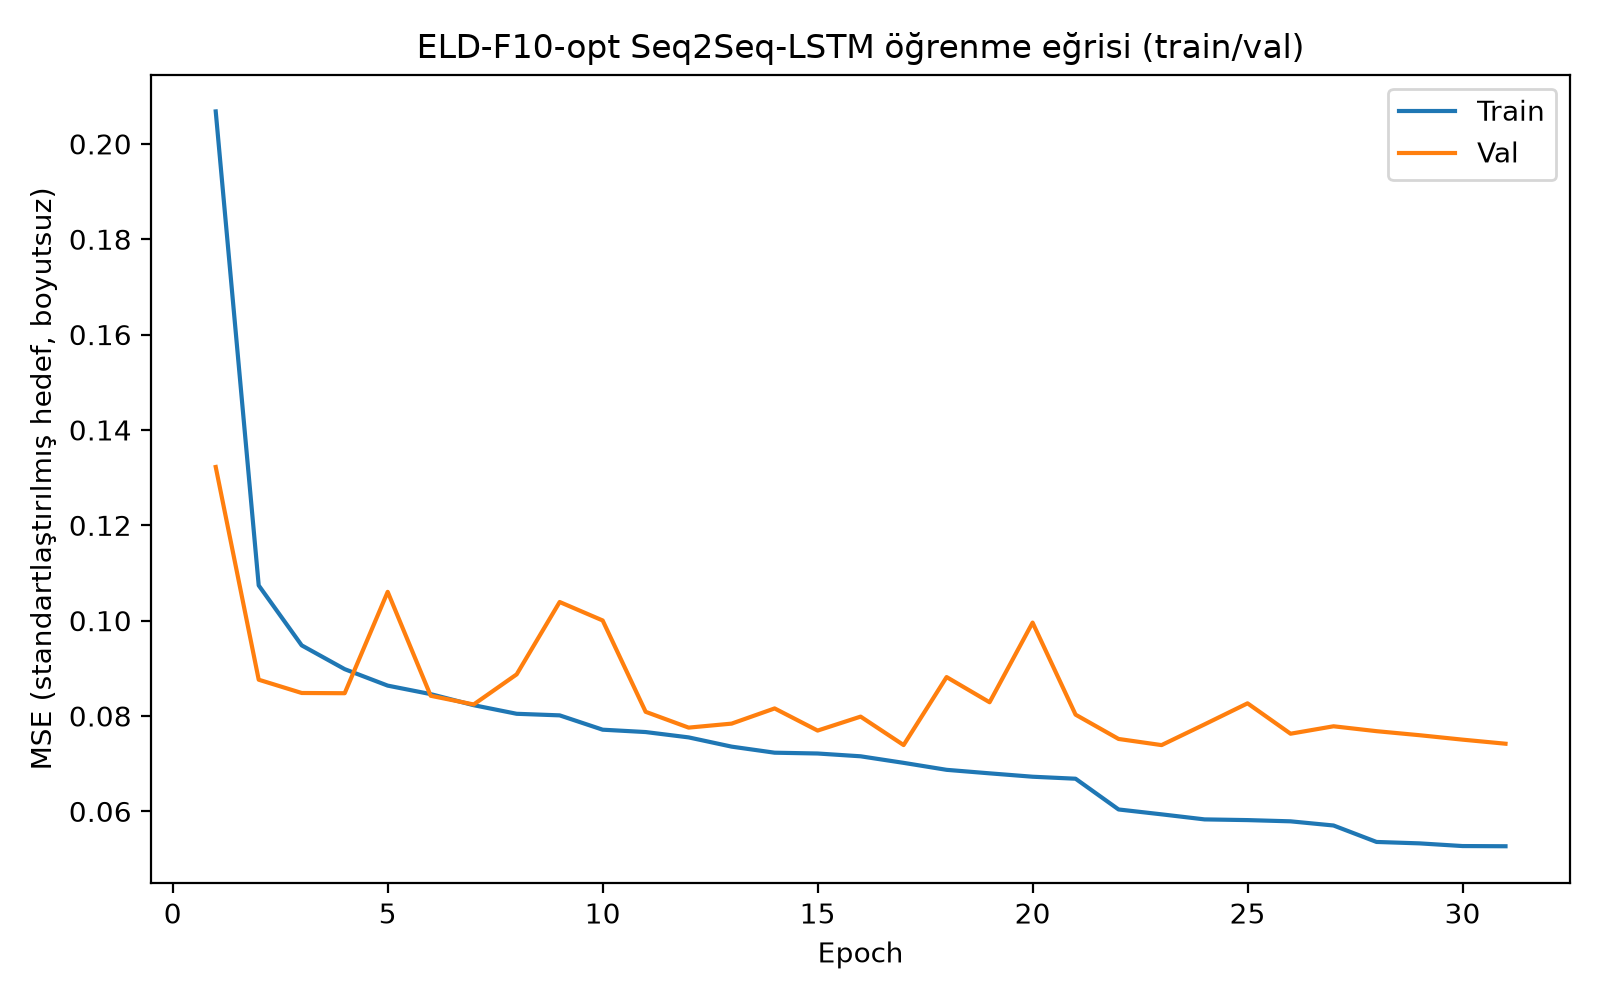

In [5]:
figures_dir = resolve_path(PROJECT_ROOT, config["paths"]["figures_dir"])
for name in ["ELD-F10-opt_learning_curve.png"]:
    if (figures_dir / name).is_file():
        print(name); display(Image(filename=str(figures_dir / name), width=650))

## 3. Bölme (kronolojik)

Train 2012–2013, val 2014-01 – 2014-06; test aralığı yalnız bilgi için gösterilir.

In [6]:
from src.core.split import chronological_split

parts = chronological_split(df, config)
display(pd.DataFrame([{"parça": k, "başlangıç": v.index.min(), "bitiş": v.index.max(), "saat": len(v)}
                      for k, v in parts.items()]))

,parça,başlangıç,bitiş,saat
0,train,2012-01-01,2013-12-31 23:00:00,17544
1,val,2014-01-01,2014-06-30 23:00:00,4344
2,test,2014-07-01,2014-12-31 23:00:00,4416


## 4. Modeller

Kadro (`src/pipelines/eld_run.py::ROSTER`): hane kadrosunun alt kümesi — Ridge, LSTM (F5-opt, 3 seed), Seq2Seq (F10-opt, 3 seed), XGBoost ve F13-ens. Eğitim hücresi varsayılan kapalı.

In [7]:
from src.pipelines import eld_run as er
from src.pipelines import evaluate_forecast as ef

display(pd.DataFrame([{"exp_id": k, "aile": v[0], "model": v[1], "öznitelik seti": v[2], "lookback": v[3]}
                      for k, v in er.ROSTER.items()]))
if RUN_TRAINING:
    import subprocess
    subprocess.run("python -m src.pipelines.eld_run --stage val".split(), check=True, cwd=PROJECT_ROOT)  # eğitim + val
else:
    print("RUN_TRAINING = False: eğitim atlandı; kayıtlı ELD ağırlıkları (models/eld/) kullanılacak.")

,exp_id,aile,model,öznitelik seti,lookback
0,ELD-F3-cal,ridge,Ridge,B,168.0
1,ELD-F5-opt,torch,LSTM,B,NaN
2,ELD-F5-opt-s7,torch,LSTM,B,NaN
3,ELD-F5-opt-s2026,torch,LSTM,B,NaN
4,ELD-F10-opt,torch,Seq2Seq-LSTM,B,NaN
5,ELD-F10-opt-s7,torch,Seq2Seq-LSTM,B,NaN
6,ELD-F10-opt-s2026,torch,Seq2Seq-LSTM,B,NaN
7,ELD-F12-L336,xgboost,XGBoost,B,336.0


RUN_TRAINING = False: eğitim atlandı; kayıtlı ELD ağırlıkları (models/eld/) kullanılacak.


## 5. Kayıtlı ağırlıklarla tahmin (val)

In [8]:
run_config = deepcopy(config)
run_config["forecast"]["xgboost"]["n_jobs"] = XGB_THREADS
predictions_dir = resolve_path(PROJECT_ROOT, config["paths"]["predictions_dir"])

def from_saved(exp_id):
    data = np.load(predictions_dir / f"{exp_id}_val.npz")
    return data["y_true"], data["y_pred"], pd.to_datetime(data["target_times"], unit="ns")

skip = {"xgboost"} if not RUN_TRAINING else set()
if not REFIT_FAST:
    skip.add("ridge")
roster = {k: v for k, v in er.ROSTER.items() if v[0] not in skip}
results = ef.all_predictions(df, run_config, "val", device, roster, er.ENSEMBLE, prefix=er.PREFIX)
for exp_id in set(er.ROSTER) - set(roster):
    results[exp_id] = from_saved(exp_id)
print("Kayıtlı dosyadan okunan:", sorted(set(er.ROSTER) - set(roster)))

# Dizi düzeyinde kontrol (ELD yükü ~1e5 kW: float32 yuvarlaması ~1e-2 kW olabilir; göreli fark raporlanır)
rows = []
for exp_id, (y_true, y_pred, times) in results.items():
    path = predictions_dir / f"{exp_id}_val.npz"
    if path.is_file():
        saved = np.load(path)
        rows.append({"exp_id": exp_id, "max_abs_diff_kw": float(np.abs(y_pred - saved["y_pred"]).max()),
                     "max_rel_diff": float((np.abs(y_pred - saved["y_pred"]) / np.abs(saved["y_pred"]).clip(1)).max())})
array_check = pd.DataFrame(rows)
display(array_check)
CHECKS.append({"kontrol": "ELD val tahminleri = kayıtlı .npz (göreli fark)", "yeni_satir": len(array_check),
               "kayitli_satir": len(array_check), "eslesen": len(array_check),
               "max_abs_fark": float(array_check["max_rel_diff"].max()),
               "tamam": float(array_check["max_rel_diff"].max()) <= TOLERANCE})

ELD-F3-cal: 4296 pencere


ELD-F5-opt: 4296 pencere


ELD-F5-opt-s7: 4296 pencere


ELD-F5-opt-s2026: 4296 pencere


ELD-F10-opt: 4296 pencere


ELD-F10-opt-s7: 4296 pencere


ELD-F10-opt-s2026: 4296 pencere
Kayıtlı dosyadan okunan: ['ELD-F12-L336']


,exp_id,max_abs_diff_kw,max_rel_diff
0,ELD-F1,0.007812,5.951120e-08
1,ELD-F2,0.007812,5.951120e-08
2,ELD-F3-cal,0.000000,0.000000e+00
3,ELD-F5-opt,0.000000,0.000000e+00
4,ELD-F5-opt-s7,0.000000,0.000000e+00
5,ELD-F5-opt-s2026,0.000000,0.000000e+00
6,ELD-F10-opt,0.000000,0.000000e+00
7,ELD-F10-opt-s7,0.000000,0.000000e+00
8,ELD-F10-opt-s2026,0.000000,0.000000e+00
9,ELD-F13-ens,0.007812,5.959844e-08


## 6. Sonuç tabloları ve figürler (val)

`summarize_levels` (h = 1, 24 saat, günlük toplam) — kayıtlı karşılığı `results/eld/tables/forecast_levels_val*.csv`.

In [9]:
levels_per_seed, levels = ef.summarize_levels(results, config["evaluation"]["mape_min_y"], er.GROUPS)
display(levels.round(2))
metric_names = ["MAE", "RMSE", "MAPE*", "sMAPE", "R2"]
compare_tables("ELD forecast_levels_val_per_seed.csv", levels_per_seed,
               pd.read_csv(tables_dir / "forecast_levels_val_per_seed.csv"), ["exp_id", "level"], metric_names)
compare_tables("ELD forecast_levels_val.csv", levels, pd.read_csv(tables_dir / "forecast_levels_val.csv"),
               ["group", "level"], [f"{m}_mean" for m in metric_names])

,group,level,n_seeds,n,MAE_mean,RMSE_mean,MAPE*_mean,sMAPE_mean,R2_mean,MAE_std,RMSE_std,MAPE*_std,sMAPE_std,R2_std
0,F1 Seasonal Naive 24,a_h1,1,4296,3063.67,6385.00,3.32,3.25,0.94,NaN,NaN,NaN,NaN,NaN
1,F1 Seasonal Naive 24,b_24h,1,4296,2970.03,5935.63,3.15,3.14,0.95,NaN,NaN,NaN,NaN,NaN
2,F1 Seasonal Naive 24,c_daily,1,180,54839.80,117914.90,2.46,2.43,0.50,NaN,NaN,NaN,NaN,NaN
3,F2 Seasonal Naive 168,a_h1,1,4296,4523.86,7841.70,4.37,4.45,0.91,NaN,NaN,NaN,NaN,NaN
4,F2 Seasonal Naive 168,b_24h,1,4296,4531.00,7844.28,4.38,4.46,0.91,NaN,NaN,NaN,NaN,NaN
5,F2 Seasonal Naive 168,c_daily,1,180,96117.67,154087.07,3.91,3.99,0.15,NaN,NaN,NaN,NaN,NaN
6,F3-cal Ridge,a_h1,1,4296,2082.21,2812.32,2.25,2.24,0.99,NaN,NaN,NaN,NaN,NaN
7,F3-cal Ridge,b_24h,1,4296,2758.37,4770.14,2.99,2.96,0.97,NaN,NaN,NaN,NaN,NaN
8,F3-cal Ridge,c_daily,1,180,56310.35,107137.99,2.50,2.46,0.59,NaN,NaN,NaN,NaN,NaN
9,F12-L336 XGBoost,a_h1,1,4296,1265.51,1680.39,1.33,1.33,1.00,NaN,NaN,NaN,NaN,NaN


True

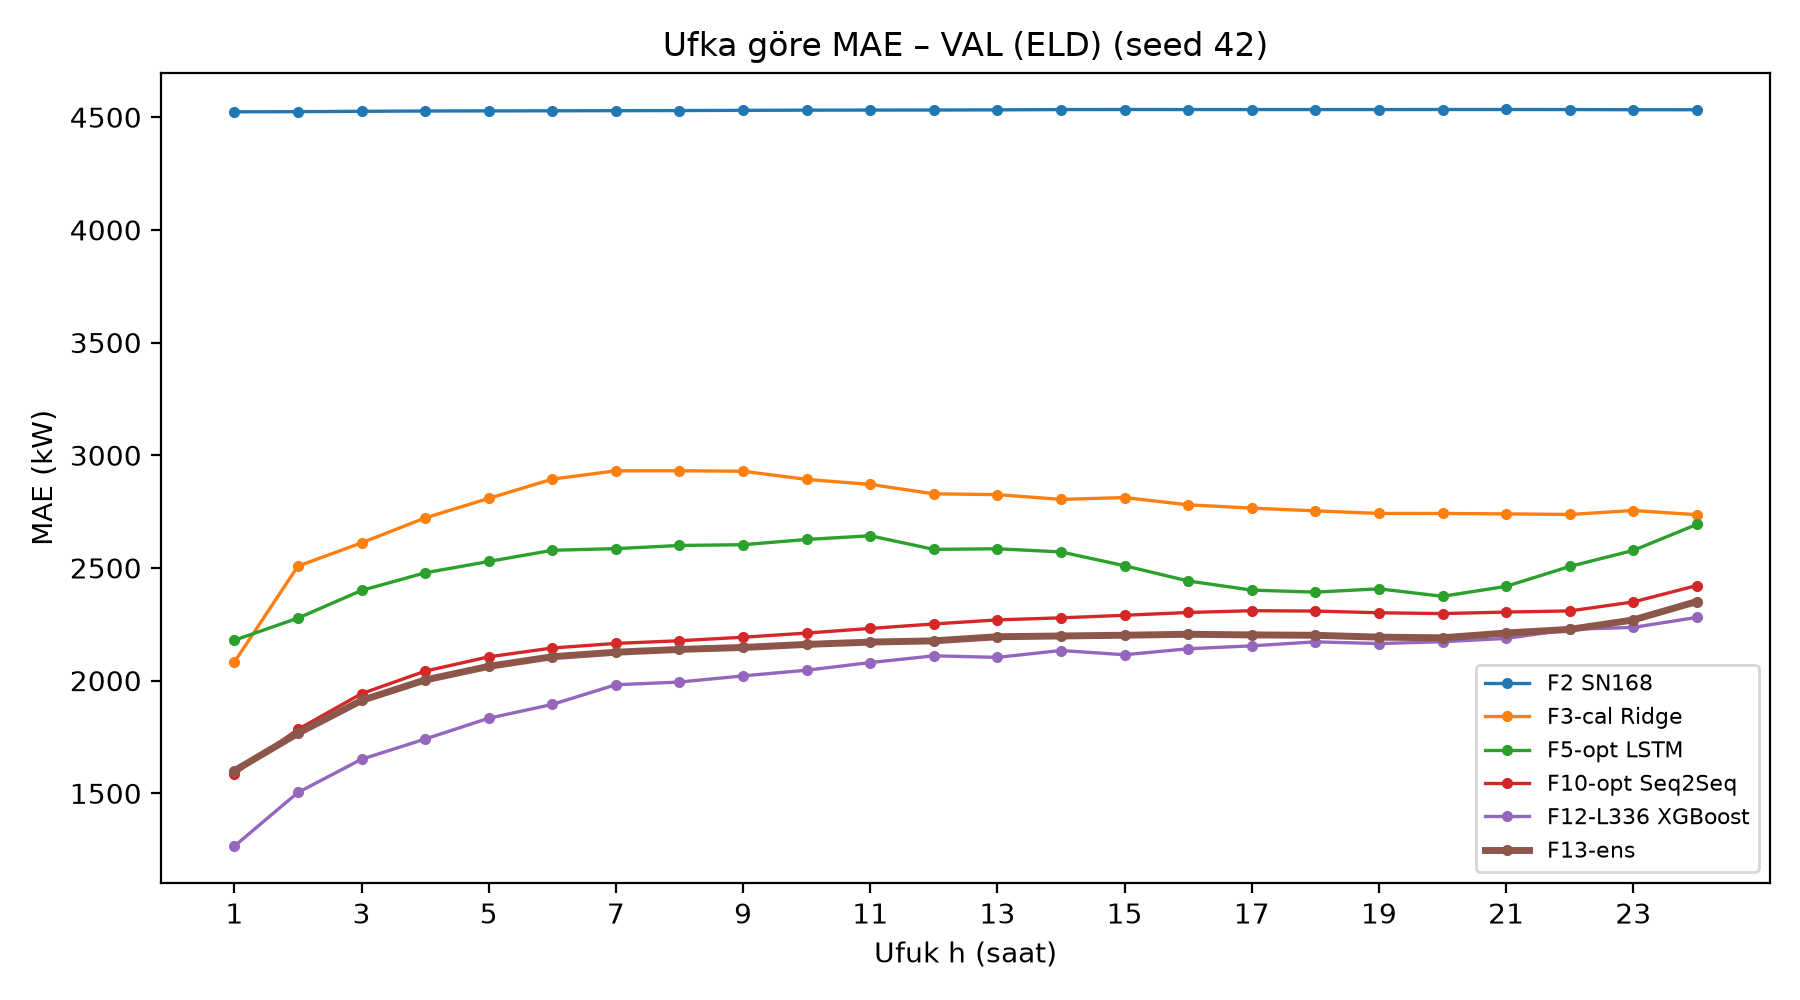

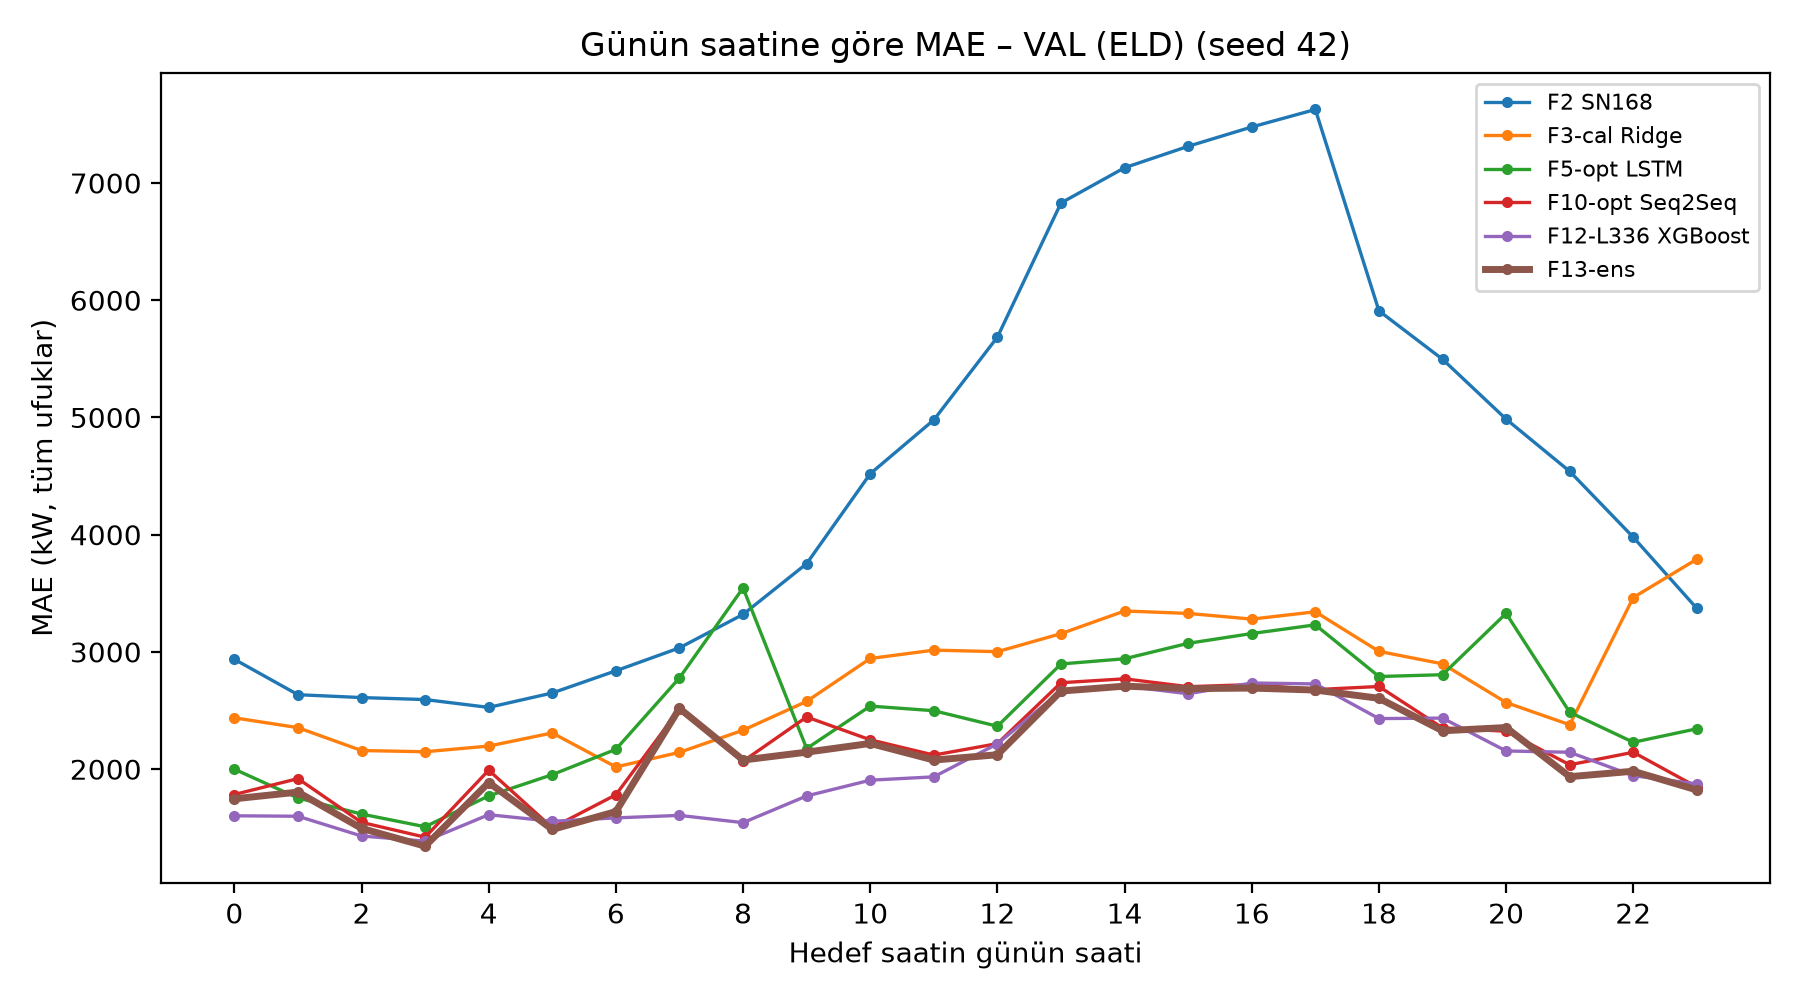

In [10]:
ef.save_error_figures(results, FIG_DIR, "val", prefix=er.PREFIX, dataset="ELD")
for name in ["ELD-F_final_val_mae_by_horizon.png", "ELD-F_final_val_mae_by_hour.png"]:
    display(Image(filename=str(FIG_DIR / name), width=750))

In [11]:
# Donmuş test ve hane–şebeke kıyas tabloları — YALNIZ OKUNUR; test burada hesaplanmaz.
display(pd.read_csv(tables_dir / "forecast_test_results.csv").round(2).head(20))
display(pd.read_csv(tables_dir / "hane_vs_sebeke_forecast.csv").round(4))

,exp_id,split,model,feature_set,lookback,windows,MAE,RMSE,MAPE*,sMAPE,R2,train_time_s,device,date,note
0,ELD-F1,test,F1 Seasonal Naive 24,B,NaN,4368,3637.62,6900.50,3.70,3.60,0.94,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
1,ELD-F2,test,F2 Seasonal Naive 168,B,NaN,4368,4851.60,7474.09,4.67,4.45,0.93,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
2,ELD-F3-cal,test,F3-cal Ridge,B,NaN,4368,3331.13,5745.56,3.47,3.35,0.96,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
3,ELD-F5-opt,test,F5-opt LSTM,B,NaN,4368,3244.24,4908.01,3.39,3.29,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
4,ELD-F5-opt-s7,test,F5-opt LSTM,B,NaN,4368,3398.32,5172.15,3.57,3.45,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
5,ELD-F5-opt-s2026,test,F5-opt LSTM,B,NaN,4368,3361.63,4876.21,3.49,3.41,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
6,ELD-F10-opt,test,F10-opt Seq2Seq,B,NaN,4368,3120.63,4517.75,3.12,3.05,0.98,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
7,ELD-F10-opt-s7,test,F10-opt Seq2Seq,B,NaN,4368,3289.40,4867.06,3.42,3.39,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
8,ELD-F10-opt-s2026,test,F10-opt Seq2Seq,B,NaN,4368,3285.80,4921.83,3.42,3.44,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen
9,ELD-F12-L336,test,F12-L336 XGBoost,B,NaN,4368,2662.23,4769.76,2.76,2.60,0.97,0.0,cuda,2026-10-31,ELD test; household ayarları aynen


,level,group,hane_MAPE,hane_sMAPE,hane_R2,hane_vs_SN168_pct,hane_n_seeds,sebeke_MAPE,sebeke_sMAPE,sebeke_R2,sebeke_vs_SN168_pct,sebeke_n_seeds
0,a_h1,F1 Seasonal Naive 24,66.2856,48.9931,-0.1362,6.5893,1,3.7025,3.6067,0.9428,24.8847,1
1,a_h1,F2 Seasonal Naive 168,75.0518,53.8152,-0.2406,0.0000,1,4.6628,4.4448,0.9327,0.0000,1
2,a_h1,F3-cal Ridge,47.5064,37.9618,0.5160,35.6892,1,2.4252,2.4080,0.9878,51.3940,1
3,a_h1,F12-L336 XGBoost,42.5346,34.1196,0.5780,41.4552,1,1.6517,1.6309,0.9935,66.4999,1
4,a_h1,F5-opt LSTM,44.5072,37.0951,0.5383,37.3068,3,2.9155,2.8811,0.9820,42.7927,3
5,a_h1,F10-opt Seq2Seq,40.7977,35.8980,0.5137,38.0592,3,2.1878,2.1958,0.9902,56.1632,3
6,a_h1,F13-ens (final),40.7064,35.4162,0.5272,38.7134,3,2.2352,2.2373,0.9899,55.5650,3
7,b_24h,F1 Seasonal Naive 24,66.2628,49.0220,-0.1366,6.7580,1,3.7010,3.6036,0.9427,25.0221,1
8,b_24h,F2 Seasonal Naive 168,75.1649,53.9352,-0.2442,0.0000,1,4.6695,4.4511,0.9328,0.0000,1
9,b_24h,F3-cal Ridge,69.1414,50.6633,0.2622,15.0046,1,3.4655,3.3501,0.9603,31.3395,1


## 7. Anomali (val)

ELD'de val tek parçadır: pencere ve olay-F1 eşiği val'in ana senaryosunda seçilir (`eld_run.anomaly_stage`, val dalı). ELD için A2 (LSTM-AE) ağırlığı yoktur; kayıtlı tablolarda da A2 yoktur (aşağıdaki "A2 atlandı" uyarıları beklenir). `REFIT_FAST = True` gerekir.

In [12]:
from src.core.inject_anomalies import train_sigma_table
from src.pipelines import anomaly_protocol as ap
from src.pipelines.evaluate_anomaly import fit_combination, fit_detectors, summarize

if REFIT_FAST:
    set_seed(config["seed"])
    fitted = fit_detectors(parts, config, device, std_source="oof")
    sigma_table = train_sigma_table(parts["train"], target)
    combination = fit_combination(parts, config, fitted, device, config["protocol"]["combination_components"],
                                  reference_split="val")
    outputs = ap.score_copies(parts, config, "val", "main", fitted, device, combination, sigma_table)
    all_windows, windows, thresholds = ap.select_on_dev(outputs, config, split="val")
    selection = pd.DataFrame({"method": list(windows), "smooth": list(windows.values()),
                              "threshold": [thresholds[m] for m in windows]})
    per_seed = all_windows[all_windows["smooth"] == all_windows["method"].map(windows)]
    anomaly_summary = summarize(per_seed, ("split", "scenario", "method", "rule", "smooth"))
    display(selection)
    display(anomaly_summary[["method", "smooth", "event_f1_mean", "event_f1_std", "f1_mean", "pr_auc_mean",
                             "roc_auc_mean"]].round(3))
    compare_tables("ELD anomaly_selection.csv (pencere, eşik)", selection,
                   pd.read_csv(tables_dir / "anomaly_selection.csv"), ["method"], ["smooth", "threshold"])
    compare_tables("ELD anomaly_val_per_seed.csv", per_seed, pd.read_csv(tables_dir / "anomaly_val_per_seed.csv"),
                   ["split", "scenario", "seed", "method"], ["event_f1", "f1", "pr_auc", "roc_auc", "threshold"])
    compare_tables("ELD anomaly_val.csv", anomaly_summary, pd.read_csv(tables_dir / "anomaly_val.csv"),
                   ["split", "scenario", "method"], ["event_f1_mean", "f1_mean", "pr_auc_mean", "roc_auc_mean"])
else:
    print("REFIT_FAST = False: anomali yeniden üretimi atlandı.")

UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2_best.pt yok; A2 atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-noAug_best.pt yok; A2-noAug atlandı.
UYARI: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini\models\eld\A2-lat8_best.pt yok; A2-lat8 atlandı.


,method,smooth,threshold
0,A0,1,14.306013
1,A3-s2s-norm,1,8.416469
2,A5-mean-z,1,14.549554


,method,smooth,event_f1_mean,event_f1_std,f1_mean,pr_auc_mean,roc_auc_mean
0,A0,1,0.851,0.039,0.728,0.702,0.954
1,A3-s2s-norm,1,0.966,0.034,0.929,0.973,0.999
2,A5-mean-z,1,0.967,0.031,0.970,0.995,1.000


In [13]:
# Donmuş kıyas tablosu — YALNIZ OKUNUR.
display(pd.read_csv(tables_dir / "hane_vs_sebeke_anomaly.csv").round(3))

,method,hane_event_f1_mean,hane_event_f1_std,hane_pr_auc_mean,hane_pr_auc_std,hane_event_recall_mean,hane_event_recall_std,hane_event_precision_mean,hane_event_precision_std,hane_smooth,sebeke_event_f1_mean,sebeke_event_f1_std,sebeke_pr_auc_mean,sebeke_pr_auc_std,sebeke_event_recall_mean,sebeke_event_recall_std,sebeke_event_precision_mean,sebeke_event_precision_std,sebeke_smooth
0,A0,0.398,0.064,0.148,0.029,0.428,0.100,0.395,0.103,3,0.860,0.017,0.761,0.098,0.808,0.050,0.924,0.044,1
1,A3-s2s-norm,0.384,0.170,0.241,0.039,0.358,0.180,0.424,0.164,3,0.927,0.012,0.978,0.005,1.000,0.000,0.864,0.020,1
2,A5-mean-z,0.463,0.048,0.213,0.036,0.582,0.069,0.389,0.061,3,0.908,0.024,0.993,0.003,0.962,0.056,0.867,0.084,1


## 8. Son kontrol: kayıtlı final tablolarla birebir karşılaştırma

In [14]:
# SON KONTROL: notebook'un ürettiği tablolar kayıtlı final tablolarla birebir mi? results/ değişti mi?
snapshot_end = results_snapshot()
changed = sorted(k for k in set(SNAPSHOT_START) | set(snapshot_end) if SNAPSHOT_START.get(k) != snapshot_end.get(k))
CHECKS.append({"kontrol": "results/ altında değişen dosya yok", "yeni_satir": len(snapshot_end),
               "kayitli_satir": len(SNAPSHOT_START), "eslesen": len(snapshot_end) - len(changed),
               "max_abs_fark": float(len(changed)), "tamam": not changed})
report = pd.DataFrame(CHECKS)
display(report)
if changed:
    print("Değişen dosyalar:", changed[:20])
assert report["tamam"].all(), "Kayıtlı sonuçlarla fark var — yukarıdaki tabloya bakın."
print("Bütün kontroller geçti: notebook çıktıları kayıtlı final tablolarla aynı; results/ değişmedi.")


,kontrol,yeni_satir,kayitli_satir,eslesen,max_abs_fark,tamam
0,ELD val tahminleri = kayıtlı .npz (göreli fark),13,13,13,5.959844e-08,True
1,ELD forecast_levels_val_per_seed.csv,39,39,39,7.275958e-12,True
2,ELD forecast_levels_val.csv,21,21,21,7.275958e-12,True
3,"ELD anomaly_selection.csv (pencere, eşik)",3,3,3,0.000000e+00,True
4,ELD anomaly_val_per_seed.csv,15,15,15,1.110223e-16,True
5,ELD anomaly_val.csv,3,3,3,1.110223e-16,True
6,results/ altında değişen dosya yok,529,529,529,0.000000e+00,True


Bütün kontroller geçti: notebook çıktıları kayıtlı final tablolarla aynı; results/ değişmedi.
